# Lab 9 - Logistic Regression

## Aim

To build a Logistic Regression classifier that predicts whether a plot is a high
priority for the PMKSY irrigation scheme, to tune its regularisation strength with
cross-validation, and to study how the decision threshold trades precision against
recall.

## Theory

Logistic Regression computes a weighted sum of the features, like linear regression,
and passes it through the **sigmoid** function to turn it into a probability between
0 and 1:

$$z = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n \qquad P(y=1) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

- The plot is predicted "high" when $P(y=1) \ge 0.5$, i.e. when $z \ge 0$.
- The weights are learned by minimising **log-loss** (cross-entropy).
- A positive coefficient pushes a plot towards "high", a negative one away from it.
- **C** is the inverse of regularisation strength: a small C keeps the weights small
  (simpler model), a large C lets them grow (closer fit to the training data).

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv` (1,540 synthetic plots in 7 districts).

**Features (X)**

| Feature | Meaning |
|---|---|
| `soil_ph` | Soil acidity (pH) |
| `soil_organic_carbon` | Soil organic carbon (g/kg) |
| `groundwater_stress_pct` | How over-used the district's groundwater is (%) |
| `rainfall_mm_avg` | Average yearly rainfall of the district (mm) |
| `land_area_ha` | Size of the plot (hectares) |
| `claim_type` | IFR / CFR / CR, one-hot encoded (CFR is the reference category) |

**Target (y):** `pmksy_high` = 1 when `pmksy_score` is 65 or more (high priority for
the PMKSY irrigation scheme), otherwise 0. About 45% of plots are "high", so the two
classes are roughly balanced and accuracy is a fair first metric.

**Method:** an 80/20 stratified train/test split (`random_state=42`). Every choice of
hyper-parameter is made with **5-fold cross-validation on the training set only**;
the test set is used once, at the end, to report the final result.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("../ml/data/labeled_dataset.csv")

features = ["soil_ph", "soil_organic_carbon", "groundwater_stress_pct",
            "rainfall_mm_avg", "land_area_ha"]

X = pd.concat([df[features],
               pd.get_dummies(df["claim_type"], prefix="claim", drop_first=True, dtype=int)], axis=1)
y = (df["pmksy_score"] >= 65).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Training samples:", len(X_train), "| Testing samples:", len(X_test))
print("Share of high-priority plots:", round(y.mean(), 3))
X.head()

Training samples: 1232 | Testing samples: 308
Share of high-priority plots: 0.455


,soil_ph,soil_organic_carbon,groundwater_stress_pct,rainfall_mm_avg,land_area_ha,claim_CR,claim_IFR
0,7.1,17.22,58.0,1150.0,2.63,0,1
1,7.4,14.40,58.0,1150.0,1.25,0,1
2,7.4,14.40,58.0,1150.0,3.00,1,0
3,7.1,17.22,58.0,1150.0,3.59,0,1
4,7.1,17.22,58.0,1150.0,1.80,0,1


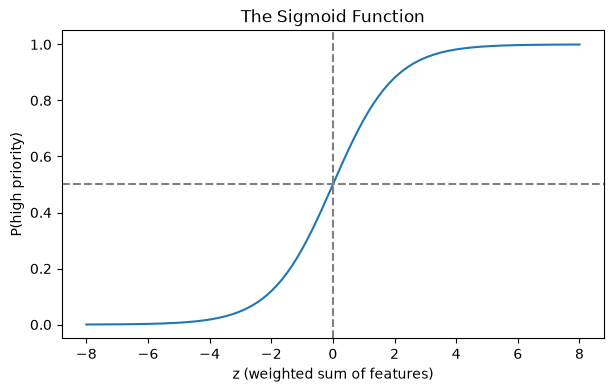

In [2]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(7, 4))
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, color="grey", linestyle="--")
plt.axvline(0, color="grey", linestyle="--")
plt.xlabel("z (weighted sum of features)")
plt.ylabel("P(high priority)")
plt.title("The Sigmoid Function")
plt.show()

## Tuning C with Cross-Validation

Features are standardised inside a pipeline, so the scaler is fitted only on the
training part of each fold. `GridSearchCV` tries each value of C with 5-fold CV and
keeps the best.

In [3]:
from sklearn.linear_model import LogisticRegression

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
grid = GridSearchCV(pipe, {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]},
                    cv=cv, scoring="accuracy")
grid.fit(X_train, y_train)

print("Best C:", grid.best_params_["logisticregression__C"])
print("Best 5-fold CV accuracy:", round(grid.best_score_, 4))
pd.DataFrame({"C": grid.cv_results_["param_logisticregression__C"],
              "CV accuracy": grid.cv_results_["mean_test_score"].round(4)})

Best C: 1
Best 5-fold CV accuracy: 0.8961


,C,CV accuracy
0,0.001,0.8652
1,0.010,0.8823
2,0.100,0.8880
3,1.000,0.8961
4,10.000,0.8945
5,100.000,0.8945


## Test Set Evaluation

Test accuracy: 0.8994

              precision    recall  f1-score   support

    Not high       0.93      0.88      0.91       168
        High       0.87      0.92      0.89       140

    accuracy                           0.90       308
   macro avg       0.90      0.90      0.90       308
weighted avg       0.90      0.90      0.90       308



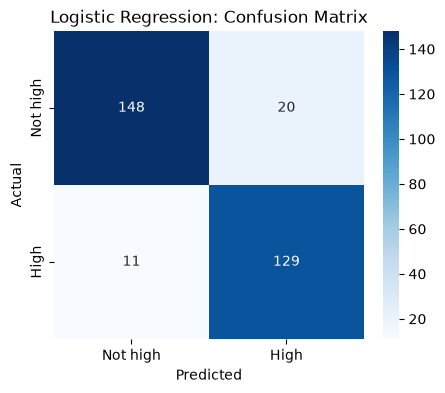

In [4]:
y_pred = grid.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Not high", "High"]))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not high", "High"], yticklabels=["Not high", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression: Confusion Matrix")
plt.show()

**How to read these metrics**

- **Accuracy**: share of all test plots classified correctly.
- **Precision (High)**: of the plots predicted "high", how many really are high.
- **Recall (High)**: of the truly high plots, how many the model caught.
- **F1**: the balance of precision and recall.
- **Confusion matrix**: rows are the true class, columns the predicted class. The
  diagonal holds correct predictions; the off-diagonal cells are the two kinds of mistake.

## Interpreting the Coefficients

Because the features were standardised, the coefficients can be compared directly:
each one is the change in the log-odds of "high priority" for a one standard deviation
increase in that feature.

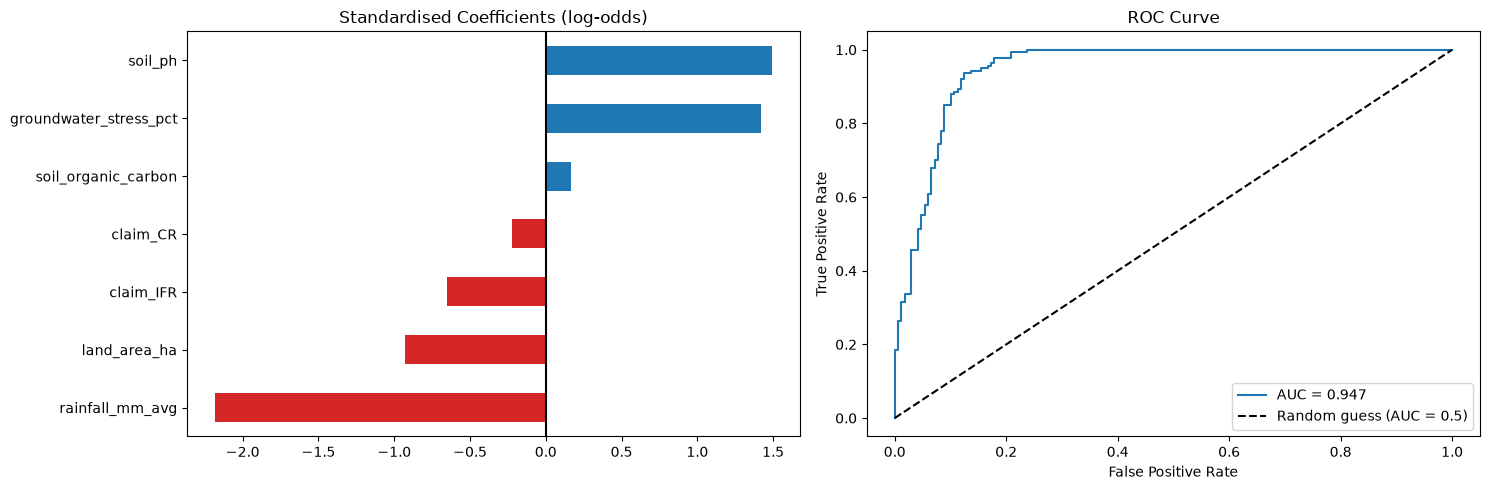

In [5]:
from sklearn.metrics import roc_curve, roc_auc_score

model = grid.best_estimator_
coef = pd.Series(model.named_steps["logisticregression"].coef_[0], index=X.columns).sort_values()

y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
coef.plot.barh(ax=axes[0], color=["tab:red" if v < 0 else "tab:blue" for v in coef])
axes[0].axvline(0, color="black")
axes[0].set_title("Standardised Coefficients (log-odds)")

axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve")
axes[1].legend()
plt.tight_layout()
plt.show()

## The Decision Threshold

The default threshold of 0.5 is not fixed. Lowering it flags more plots as "high":
recall goes up (fewer high-priority plots are missed) but precision goes down (more
false alarms). The plot below shows this trade-off. It is for illustration; in
practice the threshold would be chosen on validation data according to which mistake
is more costly.

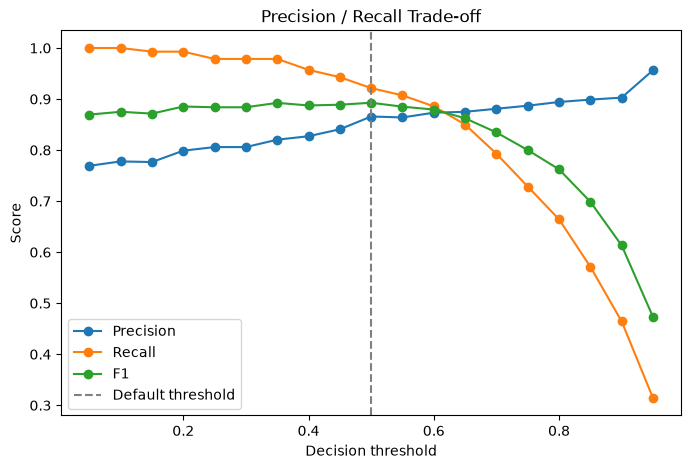

In [6]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.linspace(0.05, 0.95, 19)
trade = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": [precision_score(y_test, (y_prob >= t).astype(int), zero_division=0) for t in thresholds],
    "Recall": [recall_score(y_test, (y_prob >= t).astype(int)) for t in thresholds],
    "F1": [f1_score(y_test, (y_prob >= t).astype(int)) for t in thresholds],
})

plt.figure(figsize=(8, 5))
for col in ["Precision", "Recall", "F1"]:
    plt.plot(trade["Threshold"], trade[col], marker="o", label=col)
plt.axvline(0.5, color="grey", linestyle="--", label="Default threshold")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision / Recall Trade-off")
plt.legend()
plt.show()

## Conclusion

Logistic Regression was used to classify plots as high or not-high PMKSY priority.

| Metric | Value |
|---|---|
| Best C (5-fold CV) | 1 |
| CV accuracy | 0.896 |
| Test accuracy | 0.899 |
| Precision / Recall (High) | 0.87 / 0.92 |
| ROC AUC | shown on the ROC plot |

**Observations**

1. **Regularisation:** very small C (0.001) lowers CV accuracy to 0.865 because the
   weights are forced too close to zero (underfitting); from C = 1 upwards the accuracy
   is stable at about 0.895.
2. **Coefficients:** high groundwater stress and low rainfall push a plot towards high
   priority, while larger land area pushes it away, consistent with the PMKSY rule's
   focus on small, water-stressed, dry plots.
3. **Errors:** recall for "High" (0.92) is higher than precision (0.87): the model
   rarely misses a high-priority plot but raises some false alarms. Most mistakes are
   plots whose score is close to the 65 cut-off, where the random noise in the score
   can tip them either way.
4. **Threshold:** lowering the threshold below 0.5 raises recall further at the cost of
   precision; raising it does the opposite. The best threshold depends on which
   mistake is more costly in practice.
